# TACO 4클래스 데이터 통계

`data/taco_yolo`의 YOLO 라벨을 읽어서 split별 클래스 분포, 박스 크기·위치, 샘플 이미지를 확인한다.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

ROOT = Path.cwd()                      # data/taco_yolo 에서 실행
NAMES = ["general", "plastic", "can", "glass"]
COLORS = ["#8c8c8c", "#3a86ff", "#e63946", "#2a9d8f"]
SPLITS = ["train", "val", "test"]

images, boxes = [], []
for split in SPLITS:
    for label in sorted((ROOT / "labels" / split).glob("*.txt")):
        with Image.open(ROOT / "images" / split / f"{label.stem}.jpg") as im:
            width, height = im.size
        lines = label.read_text().split()
        images.append({"split": split, "image": label.stem, "width": width, "height": height,
                       "n_boxes": len(lines) // 5})
        for i in range(0, len(lines), 5):
            c, cx, cy, w, h = lines[i:i + 5]
            boxes.append({"split": split, "image": label.stem, "cls": NAMES[int(c)],
                          "cx": float(cx), "cy": float(cy), "w": float(w), "h": float(h)})

images, boxes = pd.DataFrame(images), pd.DataFrame(boxes)
boxes["rel_size"] = (boxes.w * boxes.h) ** 0.5     # 박스 한 변 길이 / 이미지 (0~1)
print(f"images {len(images)}, boxes {len(boxes)}")

images 1500, boxes 3942


## 1. split별 요약

In [2]:
summary = images.groupby("split").agg(images=("image", "size"), boxes=("n_boxes", "sum"),
                                     empty_images=("n_boxes", lambda s: (s == 0).sum()))
counts = boxes.pivot_table(index="split", columns="cls", values="image", aggfunc="size", fill_value=0)[NAMES]
table = summary.join(counts).loc[SPLITS]
table.loc["total"] = table.sum()
table

,images,boxes,empty_images,general,plastic,can,glass
split,,,,,,,
train,1200,3132,57,1762,1008,275,87
val,150,373,6,217,101,37,18
test,150,437,8,238,147,41,11
total,1500,3942,71,2217,1256,353,116


## 2. 클래스 분포

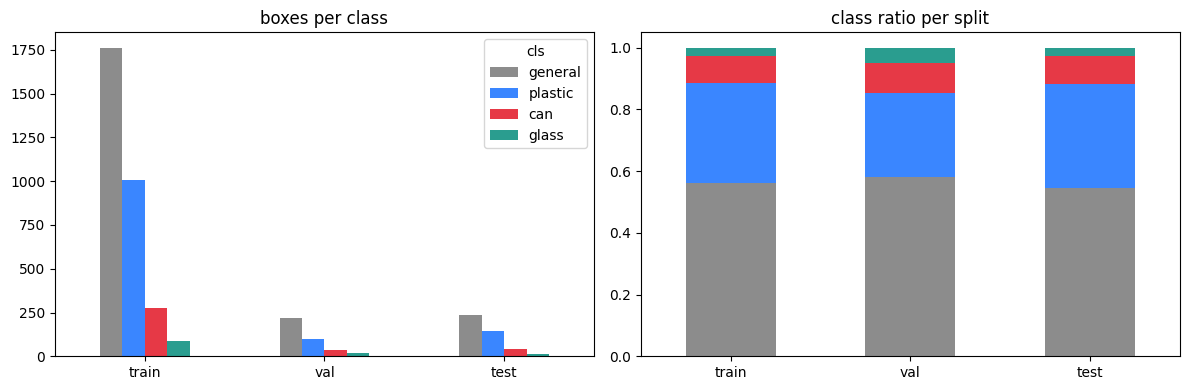

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts.loc[SPLITS].plot.bar(ax=axes[0], color=COLORS, rot=0, title="boxes per class")
ratio = counts.loc[SPLITS].div(counts.loc[SPLITS].sum(axis=1), axis=0)
ratio.plot.bar(ax=axes[1], stacked=True, color=COLORS, rot=0, title="class ratio per split", legend=False)
for ax in axes:
    ax.set_xlabel("")
plt.tight_layout()

## 3. 이미지당 박스 수 / 박스 크기

640px 기준 32px 미만 박스 비율: {'general': 0.46, 'plastic': 0.37, 'can': 0.25, 'glass': 0.16}


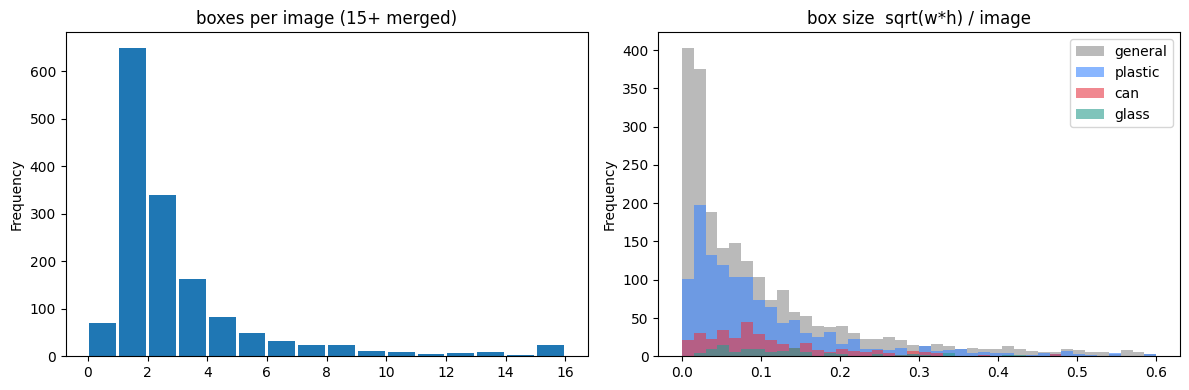

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
images.n_boxes.clip(upper=15).plot.hist(ax=axes[0], bins=range(17), rwidth=0.9,
                                        title="boxes per image (15+ merged)")
for name, color in zip(NAMES, COLORS):
    boxes.loc[boxes.cls == name, "rel_size"].plot.hist(ax=axes[1], bins=40, range=(0, 0.6),
                                                     alpha=0.6, color=color, label=name)
axes[1].set_title("box size  sqrt(w*h) / image")
axes[1].legend()
plt.tight_layout()

# 640px로 줄여서 학습할 때 32px 미만이 되는 작은 박스 비율
small = (boxes.rel_size * 640 < 32).groupby(boxes.cls).mean()[NAMES]
print("640px 기준 32px 미만 박스 비율:", small.round(2).to_dict())

## 4. 박스 위치와 이미지 크기

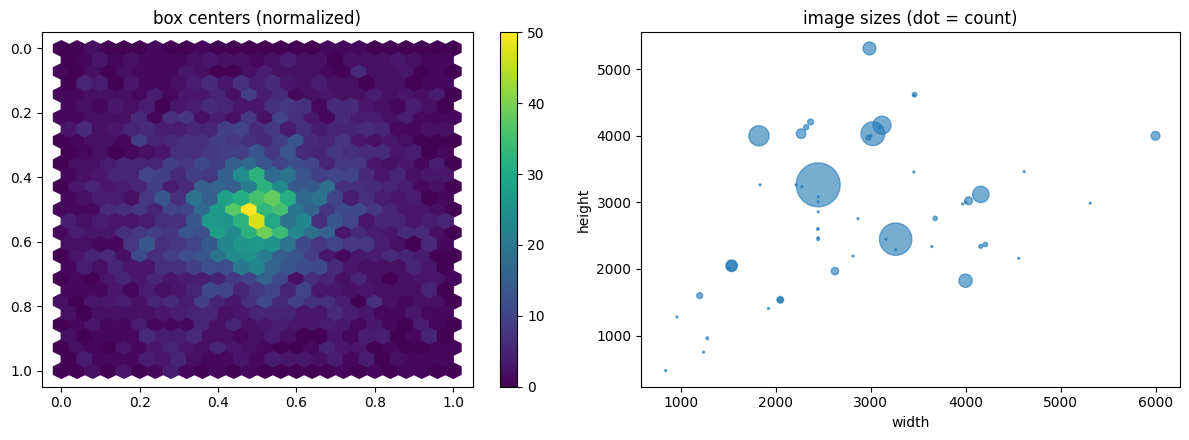

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
hb = axes[0].hexbin(boxes.cx, boxes.cy, gridsize=25, cmap="viridis", extent=(0, 1, 0, 1))
axes[0].invert_yaxis()
axes[0].set_title("box centers (normalized)")
fig.colorbar(hb, ax=axes[0])
size_counts = images.groupby(["width", "height"]).size().reset_index(name="n")
axes[1].scatter(size_counts.width, size_counts.height, s=size_counts.n * 2, alpha=0.6)
axes[1].set(title="image sizes (dot = count)", xlabel="width", ylabel="height")
plt.tight_layout()

## 5. 샘플 이미지

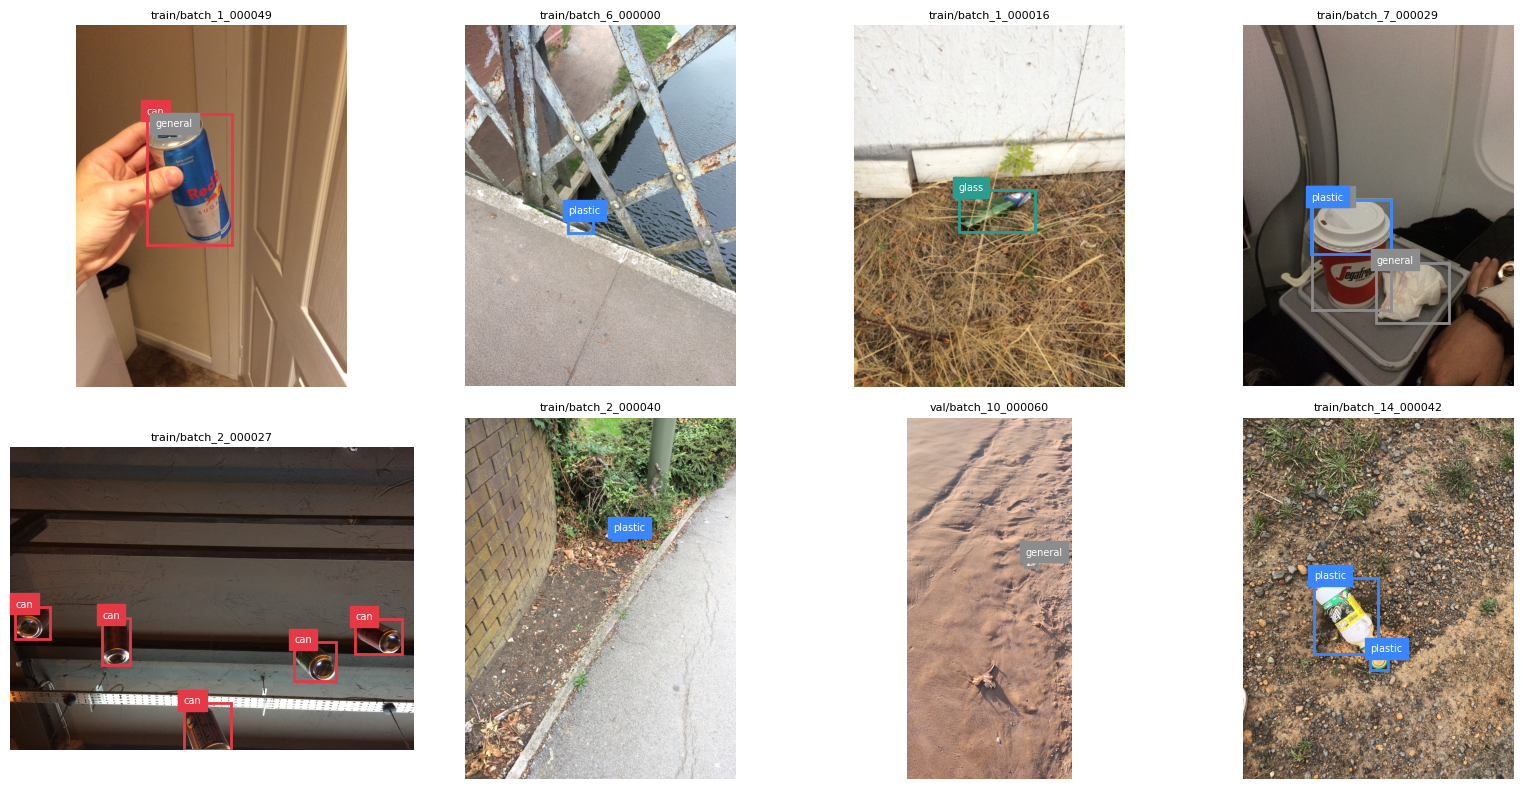

In [6]:
def show(split, image, ax):
    im = Image.open(ROOT / "images" / split / f"{image}.jpg")
    W, H = im.size
    ax.imshow(im)
    for b in boxes[(boxes.split == split) & (boxes.image == image)].itertuples():
        color = COLORS[NAMES.index(b.cls)]
        ax.add_patch(plt.Rectangle(((b.cx - b.w / 2) * W, (b.cy - b.h / 2) * H), b.w * W, b.h * H,
                                   fill=False, color=color, lw=2))
        ax.text((b.cx - b.w / 2) * W, (b.cy - b.h / 2) * H, b.cls, color="white", fontsize=7,
                backgroundcolor=color)
    ax.set_title(f"{split}/{image}", fontsize=8)
    ax.axis("off")

sample = images[images.n_boxes > 0].sample(8, random_state=0)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for row, ax in zip(sample.itertuples(), axes.flat):
    show(row.split, row.image, ax)
plt.tight_layout()